In [1]:
!python -m pip install streamlit pandas scikit-learn matplotlib wordcloud


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

%matplotlib inline

In [3]:
df = pd.read_csv(r"C:data_tugas_sentimen.csv")
print("Jumlah data :", len(df))
print("Kolom       :", list(df.columns))
df.head()

Jumlah data : 1200
Kolom       : ['created_at', 'username', 'full_text', 'sentimen']


,created_at,username,full_text,sentimen
0,2026-01-01 00:00:00,akun_contoh_0001,Udara terasa lebih bersih hari ini di Jakarta....,positif
1,2026-01-01 00:37:00,akun_contoh_0002,Kondisi Makassar: polusi udara mengganggu akti...,negatif
2,2026-01-01 01:14:00,akun_contoh_0003,Warga Samarinda menyampaikan bahwa hari ini di...,netral
3,2026-01-01 01:51:00,akun_contoh_0004,Informasi kualitas udara Semarang: program pen...,positif
4,2026-01-01 02:28:00,akun_contoh_0005,Pekanbaru menjadi lokasi pembahasan kualitas u...,negatif


In [14]:
def bersihkan_teks(teks):
    teks = str(teks)
    teks = re.sub(r"\[.*?\]", " ", teks)
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)
    teks = re.sub(r"@\w+", " ", teks)
    teks = re.sub(r"#\w+", " ", teks)
    teks = re.sub(r"\d+", " ", teks)
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)
    teks = teks.lower()
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

# Normalisasi kata tidak baku/singkatan yang umum pada teks media sosial
KAMUS_NORMALISASI = {
    "yg": "yang", "yng": "yang", "dgn": "dengan", "dg": "dengan",
    "tdk": "tidak", "gak": "tidak", "gk": "tidak", "ga": "tidak",
    "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "krn": "karena", "karna": "karena", "utk": "untuk",
    "dr": "dari", "dlm": "dalam", "jd": "jadi", "aja": "saja",
    "bgt": "banget", "bgtt": "banget", "sm": "sama", "sma": "sama",
    "tp": "tapi", "tpi": "tapi", "klo": "kalau", "kalo": "kalau",
    "blm": "belum", "udh": "sudah", "sdh": "sudah", "dah": "sudah",
    "lg": "lagi", "org": "orang", "warga2": "warga", "aja": "saja",
}

def normalisasi_teks(teks):
    """Mengubah kata singkatan/tidak baku menjadi bentuk baku."""
    tokens = teks.split()
    tokens = [KAMUS_NORMALISASI.get(k, k) for k in tokens]
    return " ".join(tokens)

df = df.dropna(subset=["full_text"]).copy()
df["clean_text"] = df["full_text"].apply(bersihkan_teks)
df["normalisasi_text"] = df["clean_text"].apply(normalisasi_teks)
df = df[df["normalisasi_text"] != ""].reset_index(drop=True)

# Tampilkan hasil agar data normalisasi benar-benar terlihat
display(df[["full_text", "clean_text", "normalisasi_text"]].head(10))

# Simpan hasil preprocessing + normalisasi ke CSV
df.to_csv("data_tugas_sentimen_normalisasi.csv", index=False, encoding="utf-8-sig")
print("File hasil normalisasi tersimpan sebagai: data_tugas_sentimen_normalisasi.csv")


,full_text,clean_text,normalisasi_text
0,Udara terasa lebih bersih hari ini di Jakarta....,udara terasa lebih bersih hari ini di jakarta ...,udara terasa lebih bersih hari ini di jakarta ...
1,Kondisi Makassar: polusi udara mengganggu akti...,kondisi makassar polusi udara mengganggu aktiv...,kondisi makassar polusi udara mengganggu aktiv...
2,Warga Samarinda menyampaikan bahwa hari ini di...,warga samarinda menyampaikan bahwa hari ini di...,warga samarinda menyampaikan bahwa hari ini di...
3,Informasi kualitas udara Semarang: program pen...,informasi kualitas udara semarang program peng...,informasi kualitas udara semarang program peng...
4,Pekanbaru menjadi lokasi pembahasan kualitas u...,pekanbaru menjadi lokasi pembahasan kualitas u...,pekanbaru menjadi lokasi pembahasan kualitas u...
5,Data indeks kualitas udara diperbarui setiap h...,data indeks kualitas udara diperbarui setiap h...,data indeks kualitas udara diperbarui setiap h...
6,Kondisi Yogyakarta: pohon yang ditanam membuat...,kondisi yogyakarta pohon yang ditanam membuat ...,kondisi yogyakarta pohon yang ditanam membuat ...
7,Warga Medan menyampaikan bahwa kabut asap meny...,warga medan menyampaikan bahwa kabut asap meny...,warga medan menyampaikan bahwa kabut asap meny...
8,Informasi kualitas udara Bogor: warga membahas...,informasi kualitas udara bogor warga membahas ...,informasi kualitas udara bogor warga membahas ...
9,Bandung menjadi lokasi pembahasan kualitas uda...,bandung menjadi lokasi pembahasan kualitas uda...,bandung menjadi lokasi pembahasan kualitas uda...


File hasil normalisasi tersimpan sebagai: data_tugas_sentimen_normalisasi.csv


In [15]:
KATA_POSITIF = [
    "membaik", "lebih bersih", "nyaman", "sejuk", "mengurangi polusi",
    "terlihat hasilnya", "membantu warga", "mulai menangani",
    "bersih", "segar", "sehat", "aman", "lega", "pulih", "bagus",
]
KATA_NEGATIF = [
    "kotor", "sesak", "membahayakan", "mengganggu", "asap tebal",
    "jarak pandang berkurang", "memperburuk", "buruk", "mengeluhkan",
    "bahaya", "parah", "rusak", "tercemar", "berbahaya", "polusi parah",
]

def beri_label(teks_bersih):
    pos = sum(teks_bersih.count(k) for k in KATA_POSITIF)
    neg = sum(teks_bersih.count(k) for k in KATA_NEGATIF)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["clean_text"].apply(beri_label)
df[["clean_text", "sentimen"]].head(10)

,clean_text,sentimen
0,udara terasa lebih bersih hari ini di jakarta ...,positif
1,kondisi makassar polusi udara mengganggu aktiv...,negatif
2,warga samarinda menyampaikan bahwa hari ini di...,netral
3,informasi kualitas udara semarang program peng...,positif
4,pekanbaru menjadi lokasi pembahasan kualitas u...,negatif
5,data indeks kualitas udara diperbarui setiap h...,netral
6,kondisi yogyakarta pohon yang ditanam membuat ...,positif
7,warga medan menyampaikan bahwa kabut asap meny...,negatif
8,informasi kualitas udara bogor warga membahas ...,netral
9,bandung menjadi lokasi pembahasan kualitas uda...,positif


sentimen
positif    400
netral     400
negatif    400
Name: count, dtype: int64


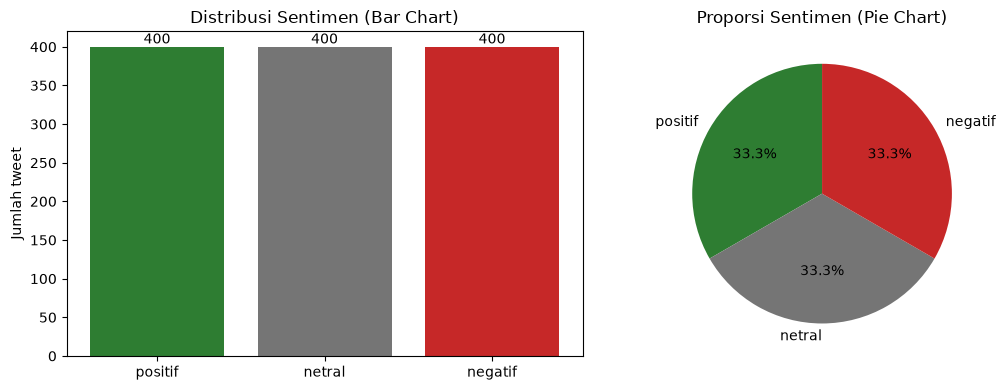

In [16]:
LABELS = ["positif", "netral", "negatif"]
WARNA = {"positif": "#2e7d32", "netral": "#757575", "negatif": "#c62828"}

dist = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
print(dist)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(dist.index, dist.values, color=[WARNA[l] for l in dist.index])
axes[0].bar_label(bars)
axes[0].set_title("Distribusi Sentimen (Bar Chart)")
axes[0].set_ylabel("Jumlah tweet")

axes[1].pie(dist.values, labels=dist.index, autopct="%1.1f%%", startangle=90,
            colors=[WARNA[l] for l in dist.index])
axes[1].set_title("Proporsi Sentimen (Pie Chart)")

plt.tight_layout()
plt.show()

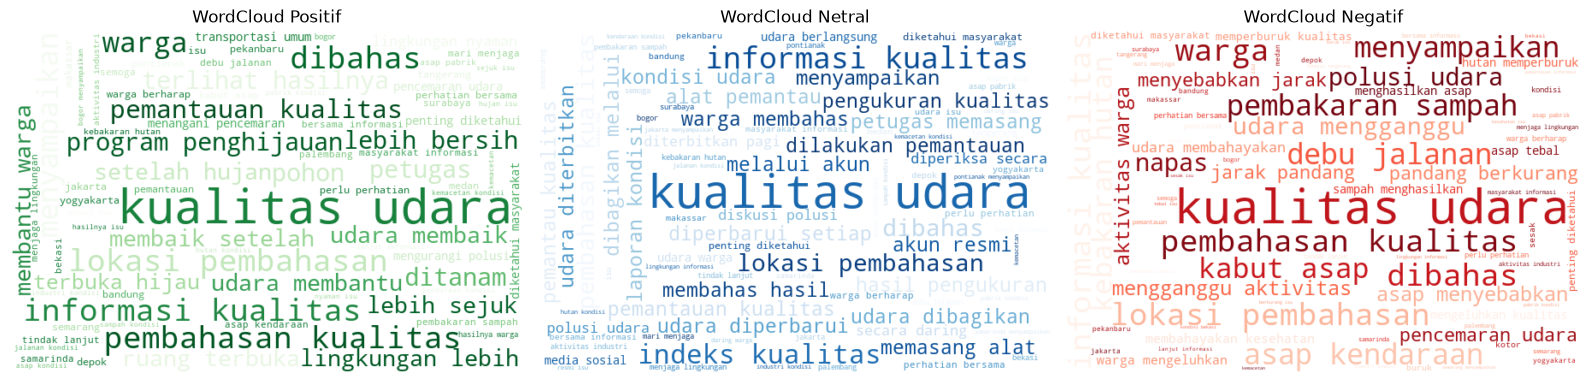

In [17]:
STOPWORDS = {
    "yang", "di", "dan", "ini", "itu", "ada", "untuk", "dengan", "dari", "pada",
    "adalah", "terkait", "bahwa", "hari", "ke", "oleh", "dapat", "mulai",
    "menjadi", "terasa", "membuat", "data", "contoh", "sintetis",
}
CMAP = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lab in zip(axes, LABELS):
    teks_kelas = " ".join(df.loc[df["sentimen"] == lab, "clean_text"])
    ax.set_title(f"WordCloud {lab.capitalize()}")
    ax.axis("off")
    if not teks_kelas.strip():
        continue
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap=CMAP[lab], stopwords=STOPWORDS,
                   random_state=1).generate(teks_kelas)
    ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentimen"],
    test_size=0.2, random_state=42, stratify=df["sentimen"]
)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

# TF-IDF: mengubah teks menjadi fitur numerik.
# norm=None digunakan agar proses normalisasi dilakukan secara eksplisit
# menggunakan Normalizer pada baris berikutnya.
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    norm=None
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Normalisasi L2:
# setiap vektor dokumen memiliki panjang (norm) 1.
normalizer = Normalizer(norm="l2")
X_train_norm = normalizer.fit_transform(X_train_tfidf)
X_test_norm = normalizer.transform(X_test_tfidf)

print("Ukuran fitur :", X_train_norm.shape)
print("Normalisasi  : L2")

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
)
mlp.fit(X_train_norm, y_train)

y_pred = mlp.predict(X_test_norm)
print("Pelatihan selesai. Iterasi:", mlp.n_iter_)


Data latih: 960 | Data uji: 240
Ukuran fitur : (960, 815)
Normalisasi  : L2
Pelatihan selesai. Iterasi: 82


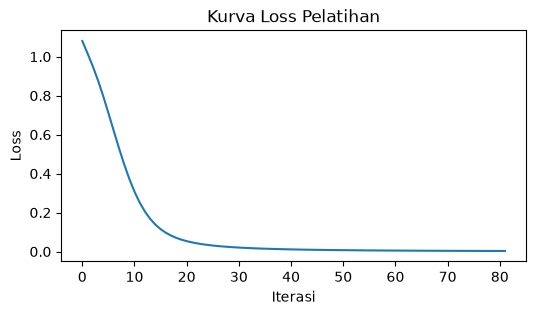

In [19]:
plt.figure(figsize=(6, 3))
plt.plot(mlp.loss_curve_)
plt.title("Kurva Loss Pelatihan")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.show()

In [20]:
kelas = [l for l in LABELS if l in set(y_test)]

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, sup = precision_recall_fscore_support(
    y_test, y_pred, labels=kelas, zero_division=0)
p_m, r_m, f_m, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0)

print(f"Akurasi          : {acc:.4f}")
print(f"Presisi (macro)  : {p_m:.4f}")
print(f"Recall (macro)   : {r_m:.4f}")
print(f"F1-Score (macro) : {f_m:.4f}\n")

tabel = pd.DataFrame({"Presisi": prec, "Recall": rec, "F1-Score": f1, "Support": sup},
                     index=kelas)
display(tabel.round(4))

print(classification_report(y_test, y_pred, labels=kelas, zero_division=0))

Akurasi          : 1.0000
Presisi (macro)  : 1.0000
Recall (macro)   : 1.0000
F1-Score (macro) : 1.0000



,Presisi,Recall,F1-Score,Support
positif,1.0,1.0,1.0,80
netral,1.0,1.0,1.0,80
negatif,1.0,1.0,1.0,80


              precision    recall  f1-score   support

     positif       1.00      1.00      1.00        80
      netral       1.00      1.00      1.00        80
     negatif       1.00      1.00      1.00        80

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



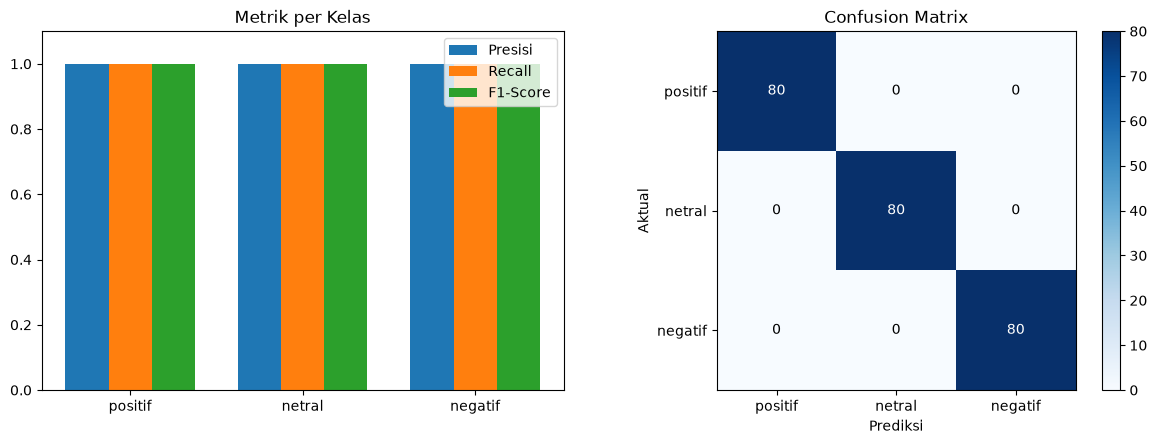

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Grafik metrik per kelas
x = np.arange(len(kelas)); w = 0.25
axes[0].bar(x - w, prec, w, label="Presisi")
axes[0].bar(x,     rec,  w, label="Recall")
axes[0].bar(x + w, f1,   w, label="F1-Score")
axes[0].set_xticks(x); axes[0].set_xticklabels(kelas)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik per Kelas")
axes[0].legend()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=kelas)
im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(kelas))); axes[1].set_yticks(range(len(kelas)))
axes[1].set_xticklabels(kelas); axes[1].set_yticklabels(kelas)
axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
axes[1].set_title("Confusion Matrix")
for i in range(len(kelas)):
    for j in range(len(kelas)):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.show()

In [22]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi_sentimen(teks):
    bersih = bersihkan_teks(teks)
    if not bersih:
        print("Teks kosong setelah dibersihkan.")
        return

    vec_tfidf = tfidf.transform([bersih])
    vec_norm = normalizer.transform(vec_tfidf)

    hasil = mlp.predict(vec_norm)[0]
    proba = mlp.predict_proba(vec_norm)[0]

    print("Teks asli         :", teks)
    print("Setelah normalisasi:", normalisasi_teks(teks))
    print("Setelah cleansing  :", bersih)
    print(f"\nHasil prediksi : {EMOJI[hasil]} {hasil.upper()}\n")

    for c, p in sorted(zip(mlp.classes_, proba), key=lambda t: -t[1]):
        print(f"  {EMOJI[c]} {c:<8} {p:.2%}")


teks_baru = "Udara terasa lebih bersih hari ini setelah hujan"
prediksi_sentimen(teks_baru)


Teks asli         : Udara terasa lebih bersih hari ini setelah hujan
Setelah normalisasi: Udara terasa lebih bersih hari ini setelah hujan
Setelah cleansing  : udara terasa lebih bersih hari ini setelah hujan

Hasil prediksi : 😊 POSITIF

  😊 positif  99.87%
  😐 netral   0.08%
  😠 negatif  0.06%


In [23]:
# Coba beberapa contoh sekaligus
contoh = [
    "Asap kendaraan membuat udara terasa kotor dan sesak",
    "Laporan kondisi udara diterbitkan pagi ini",
    "Program penghijauan mulai terlihat hasilnya, lingkungan jadi nyaman",
]
for t in contoh:
    prediksi_sentimen(t)
    print("-" * 50)

Teks asli         : Asap kendaraan membuat udara terasa kotor dan sesak
Setelah normalisasi: Asap kendaraan membuat udara terasa kotor dan sesak
Setelah cleansing  : asap kendaraan membuat udara terasa kotor dan sesak

Hasil prediksi : 😠 NEGATIF

  😠 negatif  99.86%
  😊 positif  0.11%
  😐 netral   0.03%
--------------------------------------------------
Teks asli         : Laporan kondisi udara diterbitkan pagi ini
Setelah normalisasi: Laporan kondisi udara diterbitkan pagi ini
Setelah cleansing  : laporan kondisi udara diterbitkan pagi ini

Hasil prediksi : 😐 NETRAL

  😐 netral   99.82%
  😊 positif  0.10%
  😠 negatif  0.08%
--------------------------------------------------
Teks asli         : Program penghijauan mulai terlihat hasilnya, lingkungan jadi nyaman
Setelah normalisasi: Program penghijauan mulai terlihat hasilnya, lingkungan jadi nyaman
Setelah cleansing  : program penghijauan mulai terlihat hasilnya lingkungan jadi nyaman

Hasil prediksi : 😊 POSITIF

  😊 positif  99.88%
  